# L'espace-temps, surface d'un univers 5D

Les calculs de la fiche [`README.md`](README.md) : la métrique induite d'une surface plongée, puis le spectre de Kaluza-Klein sur une grille régulière.

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

sp.init_printing(use_latex="mathjax")

# Palette Smoothop (docs/Style.md § Les couleurs)
S3, O3, V5, K7 = "#0B85A6", "#CC6318", "#8D2EFF", "#606060"
plt.rcParams.update({"figure.figsize": (7, 3.6), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})

## 1. La métrique induite

$$g_{\mu\nu} = G_{AB}\,\partial_\mu X^A\,\partial_\nu X^B$$

Une fonction générale : la jacobienne du plongement, contractée avec la métrique 5D.

In [2]:
def metrique_induite(X, coords, G):
    J = sp.Matrix(X).jacobian(coords)
    return sp.simplify(J.T * G * J)

t, tau, chi, th, ph = sp.symbols("t tau chi theta phi", real=True)
ell = sp.symbols("ell", positive=True)
# un point de la sphère unité S^3
omega = [sp.cos(chi), sp.sin(chi)*sp.cos(th),
         sp.sin(chi)*sp.sin(th)*sp.cos(ph), sp.sin(chi)*sp.sin(th)*sp.sin(ph)]

## 2. De Sitter, hyperboloïde de Minkowski 5D

$X^0 = \ell\sinh(t/\ell)$, $X^i = \ell\cosh(t/\ell)\,\omega^i$, dans $G = \operatorname{diag}(-1,1,1,1,1)$.

In [3]:
X_dS = [ell*sp.sinh(t/ell)] + [ell*sp.cosh(t/ell)*w for w in omega]
G_mink = sp.diag(-1, 1, 1, 1, 1)
print("contrainte :", sp.simplify((sp.Matrix(X_dS).T * G_mink * sp.Matrix(X_dS))[0]))
g_dS = metrique_induite(X_dS, [t, chi, th, ph], G_mink)
g_dS

contrainte : ell**2


⎡-1         0                    0                            0               ⎤
⎢                                                                             ⎥
⎢       2     2⎛ t ⎞                                                          ⎥
⎢0   ell ⋅cosh ⎜───⎟             0                            0               ⎥
⎢              ⎝ell⎠                                                          ⎥
⎢                                                                             ⎥
⎢                        2    2        2⎛ t ⎞                                 ⎥
⎢0          0         ell ⋅sin (χ)⋅cosh ⎜───⎟                 0               ⎥
⎢                                       ⎝ell⎠                                 ⎥
⎢                                                                             ⎥
⎢                                                 2    2       2        2⎛ t ⎞⎥
⎢0          0                    0             ell ⋅sin (χ)⋅sin (θ)⋅cosh ⎜───⎟⎥
⎣                                       

On lit $ds^2 = -dt^2 + \ell^2\cosh^2(t/\ell)\,d\Omega_3^2$ : un univers dont la taille passe par un minimum $\ell$ puis croît exponentiellement.

## 3. La rotation de Wick : la 4-sphère dans $\mathbb{R}^5$

Même chose, en euclidien : $Y^0 = \ell\sin(\tau/\ell)$, $Y^i = \ell\cos(\tau/\ell)\,\omega^i$, dans $G = \delta$.

In [4]:
Y_S4 = [ell*sp.sin(tau/ell)] + [ell*sp.cos(tau/ell)*w for w in omega]
print("contrainte :", sp.simplify(sum(y**2 for y in Y_S4)))
g_S4 = metrique_induite(Y_S4, [tau, chi, th, ph], sp.eye(5))
g_S4

contrainte : ell**2


⎡1        0                   0                           0               ⎤
⎢                                                                         ⎥
⎢      2    2⎛ τ ⎞                                                        ⎥
⎢0  ell ⋅cos ⎜───⎟            0                           0               ⎥
⎢            ⎝ell⎠                                                        ⎥
⎢                                                                         ⎥
⎢                      2    2       2⎛ τ ⎞                                ⎥
⎢0        0         ell ⋅sin (χ)⋅cos ⎜───⎟                0               ⎥
⎢                                    ⎝ell⎠                                ⎥
⎢                                                                         ⎥
⎢                                              2    2       2       2⎛ τ ⎞⎥
⎢0        0                   0             ell ⋅sin (χ)⋅sin (θ)⋅cos ⎜───⎟⎥
⎣                                                                    ⎝ell⎠⎦

Vérification : la métrique de de Sitter, avec $t = -i\tau$ (donc $dt^2 = -d\tau^2$, d'où le facteur $-1$ sur la composante $tt$), redonne exactement celle de la 4-sphère.

In [5]:
wick = sp.Matrix(g_dS.subs(t, -sp.I*tau))
wick[0, 0] = -wick[0, 0]          # dt^2 = -dtau^2
sp.simplify(wick - g_S4)

⎡0  0  0  0⎤
⎢          ⎥
⎢0  0  0  0⎥
⎢          ⎥
⎢0  0  0  0⎥
⎢          ⎥
⎣0  0  0  0⎦

## 4. Kaluza-Klein sur une grille

La cinquième dimension est un cercle de rayon $R = 1$ discrétisé en $N$ sites de pas $a = 2\pi R/N$. Les masses des modes sont les racines des valeurs propres du laplacien discret sur l'anneau. Attendu :

$$m_n = \frac{2}{a}\left|\sin\frac{\pi n}{N}\right| \quad\text{contre}\quad m_n = \frac{n}{R}\ \text{(continu)}.$$

écart max. diagonalisation / formule : 5.773159728050814e-15


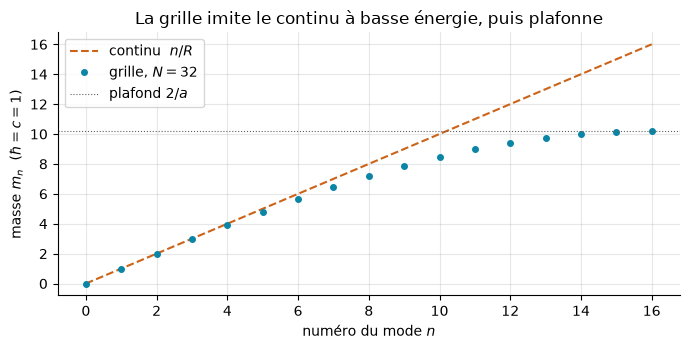

In [6]:
R, N = 1.0, 32
a = 2*np.pi*R / N
anneau = (2*np.eye(N) - np.roll(np.eye(N), 1, axis=1) - np.roll(np.eye(N), -1, axis=1)) / a**2
masses = np.sqrt(np.clip(np.linalg.eigvalsh(anneau), 0, None))

n = np.arange(N)
formule = 2/a * np.abs(np.sin(np.pi*n/N))
print("écart max. diagonalisation / formule :", np.abs(np.sort(masses) - np.sort(formule)).max())

n_aff = np.arange(N//2 + 1)
plt.plot(n_aff, n_aff/R, color=O3, ls="--", label="continu  $n/R$")
plt.plot(n_aff, 2/a*np.sin(np.pi*n_aff/N), "o", color=S3, ms=4, label=fr"grille, $N = {N}$")
plt.axhline(2/a, color=K7, lw=0.8, ls=":", label=r"plafond $2/a$")
plt.xlabel("numéro du mode $n$"); plt.ylabel(r"masse $m_n$  ($\hbar = c = 1$)")
plt.title("La grille imite le continu à basse énergie, puis plafonne")
plt.legend(); plt.tight_layout()

**Lecture.** Les premiers modes ne voient pas la grille. Les derniers la voient très bien : aucune masse ne dépasse $2/a$. Une grille régulière porte en elle une énergie maximale, qui servira de coupure dans [`../energie-du-vide/`](../energie-du-vide/).